<a href="https://colab.research.google.com/github/Kufala/Fraud-Detection/blob/main/Attrition_Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier


In [ ]:
df =  pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

In [ ]:
df.shape

(1470, 35)

In [ ]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [ ]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [ ]:
df.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [ ]:
#Encode Target column with Labelencoder
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Attrition'] = le.fit_transform(df['Attrition'])


In [ ]:
df['Attrition'].unique()

array([1, 0])

In [ ]:
X = df.drop('Attrition', axis=1)
y = df['Attrition']

In [ ]:
#6.Identify Numeric vs Categorical Columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

In [ ]:
#7. Preprocessing Pipeline
# Scale numeric
# One-hot encode categorical
preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

NameError: name 'ColumnTransformer' is not defined

In [ ]:
# Train-test split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
#LOGISTIC REGRESSION
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

clf = LogisticRegression(max_iter=1000)

# full pipeline
clf = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', LogisticRegression(max_iter=1000))
])

# fit model
clf.fit(X_train, y_train)

# predict
y_pred = clf.predict(X_test)


print("Accuracy:",accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.8605442176870748
              precision    recall  f1-score   support

           0       0.88      0.96      0.92       247
           1       0.62      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.75      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294



In [ ]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_pred)

array([[237,  10],
       [ 31,  16]])

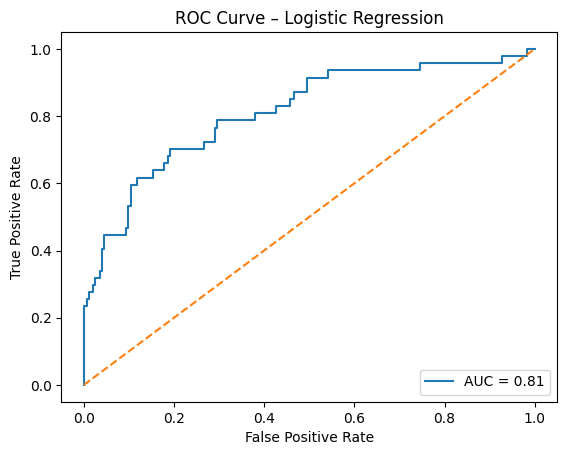

In [ ]:
# ROC curve
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
y_pred_proba = clf.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Logistic Regression")
plt.legend(loc="lower right")
plt.show()


In [ ]:
#RANDOM FOREST CLASSIFIER
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(n_estimators=100, random_state=42)

# full pipeline

clf = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', RandomForestClassifier(n_estimators=100, random_state=42))
])

# fit model
clf.fit(X_train, y_train)

# predict
y_pred = clf.predict(X_test)


print("Accuracy:",accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.8469387755102041
              precision    recall  f1-score   support

           0       0.86      0.98      0.91       247
           1       0.58      0.15      0.24        47

    accuracy                           0.85       294
   macro avg       0.72      0.56      0.58       294
weighted avg       0.81      0.85      0.81       294



In [ ]:
#Confussion Matrix
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_pred)

array([[242,   5],
       [ 40,   7]])

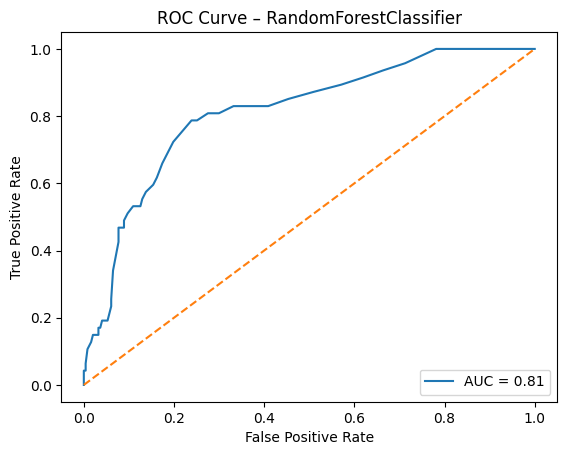

In [ ]:
svm_clf = Pipeline(steps=[
    ('preprocess', preprocess),    # SAME preprocess used before
    ('model', RandomForestClassifier())               # RandomForestClassifier model
])

# ROC curve
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
y_pred_proba = clf.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – RandomForestClassifier")
plt.legend(loc="lower right")
plt.show()


In [ ]:
#SUPPORT VECTOR MECHANIC (SVM)

from sklearn.svm import SVC
svm_clf = SVC(kernel='rbf', C=1.0, gamma='scale')


# full pipeline

clf = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

# fit model
clf.fit(X_train, y_train)

# predict
y_pred = clf.predict(X_test)


print("Accuracy:",accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))




Accuracy: 0.8639455782312925
              precision    recall  f1-score   support

           0       0.87      0.99      0.92       247
           1       0.77      0.21      0.33        47

    accuracy                           0.86       294
   macro avg       0.82      0.60      0.63       294
weighted avg       0.85      0.86      0.83       294



In [ ]:
#Confussion Matrix
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_pred)

array([[244,   3],
       [ 37,  10]])

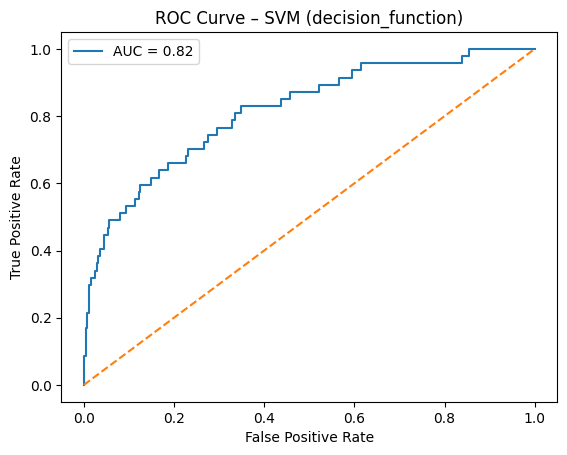

In [ ]:



svm_clf = Pipeline(steps=[
    ('preprocess', preprocess),    # SAME preprocess used before
    ('model', SVC())               # SVM model
])


svm_clf.fit(X_train, y_train)

# use decision_function instead of predict_proba
y_scores = svm_clf.decision_function(X_test)

fpr, tpr, thresholds = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – SVM (decision_function)")
plt.legend()
plt.show()


In [ ]:
# NEURAL NETWORK MODEL
from sklearn.neural_network import MLPClassifier
mlp = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)


# full pipeline

clf = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model',MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
))
])

# fit model
clf.fit(X_train, y_train)

# predict
y_pred = clf.predict(X_test)


print("Accuracy:",accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))






Accuracy: 0.8401360544217688
              precision    recall  f1-score   support

           0       0.90      0.91      0.91       247
           1       0.50      0.47      0.48        47

    accuracy                           0.84       294
   macro avg       0.70      0.69      0.69       294
weighted avg       0.84      0.84      0.84       294



In [ ]:
#Confusion matrix
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_pred)

array([[225,  22],
       [ 25,  22]])

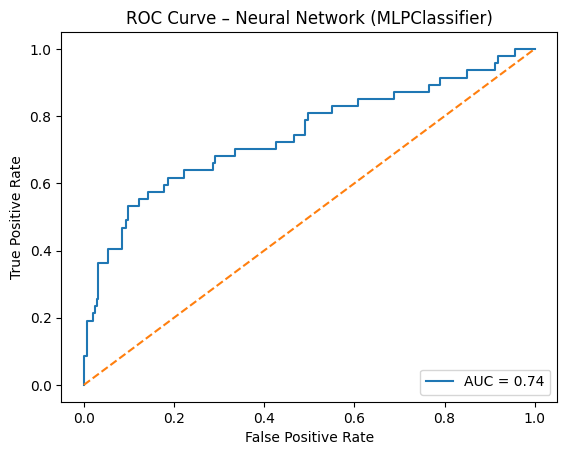

In [ ]:
# Fit model
clf.fit(X_train, y_train)

# Get predicted probabilities for the positive class (1)
y_pred_proba = clf.predict_proba(X_test)[:, 1]

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

# Plot ROC
plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Neural Network (MLPClassifier)")
plt.legend(loc="lower right")
plt.show()


In [ ]:
# Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB
nb_clf = GaussianNB()

# full pipeline

clf = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model',  GaussianNB())
])

# fit model
clf.fit(X_train, y_train)

# predict
y_pred = clf.predict(X_test)


print("Accuracy:",accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))





Accuracy: 0.6462585034013606
              precision    recall  f1-score   support

           0       0.91      0.64      0.75       247
           1       0.26      0.66      0.37        47

    accuracy                           0.65       294
   macro avg       0.58      0.65      0.56       294
weighted avg       0.80      0.65      0.69       294



In [ ]:
#Confussion Matrix
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_pred)

array([[159,  88],
       [ 16,  31]])

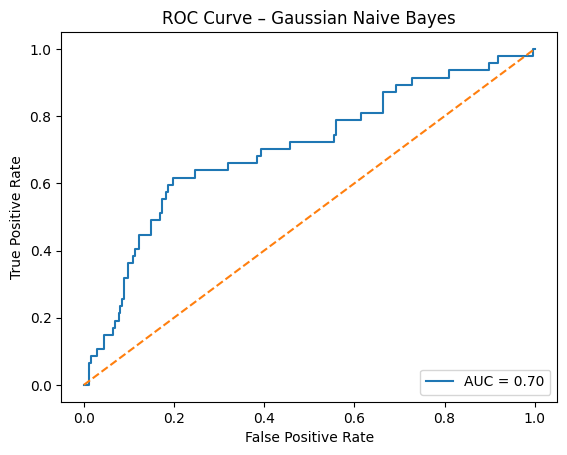

In [ ]:
# Fit the model
clf.fit(X_train, y_train)

# Predict probabilities for class 1
y_pred_proba = clf.predict_proba(X_test)[:, 1]

# ROC calculations
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Gaussian Naive Bayes")
plt.legend(loc="lower right")
plt.show()
